# Grouped LBP Bins

**Idea:** the LBP histogram has 10 to 26 bins per scale. Many of them mean similar things, so we group them into 4 easy-to-read types and use the share of pixels in each type as the feature.

| Group | What the pixel's neighborhood looks like | Likely in |
|---|---|---|
| **spot** | center is brighter than all neighbors (or darker than all) | scales, speckles, eyes |
| **corner** | center differs from only a few neighbors | tips, bends, line ends |
| **edge** | center differs from about half of its neighbors | boundaries, straight edges |
| **noisy** | no clean pattern | fur, feathers, clutter |

We also add the **entropy** of the full histogram (a single number for how random the texture is).

**Question:** can these 12 to 15 numbers match the 54-number raw LBP from before?

Steps: 1. setup, 2. how the grouping works, 3. compute, 4. look at it, 5. signal test, 6. save.

In [14]:
%pip install -q numpy pandas matplotlib pillow scikit-image scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 1. Setup

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from skimage.feature import local_binary_pattern
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

In [16]:
SEED = 42
IMG_SIZE = 224                           
LBP_PARAMS = [(8, 1), (16, 2), (24, 3)]  #Intial choices, (P neighbors, R radius)
HSV_BINS = 16
LABEL_COLUMN = "supercategory"
META_PATH = Path("./sample_images/metadata.csv")
FEATURE_DIR = Path("./features")
FEATURE_DIR.mkdir(exist_ok=True)

IMG_DIR = Path("./sample_images/images")
if not IMG_DIR.exists():
    IMG_DIR = Path("../sample/images")

metadata = pd.read_csv(META_PATH, index_col=0)[["image_id", "file_name", "common_name", LABEL_COLUMN]]
y = metadata[LABEL_COLUMN].to_numpy()
categories = sorted(set(y))
print(len(metadata), "images,", len(categories), "classes")

2200 images, 11 classes


## 2. Creating the "filter"

`method="uniform"` gives each pixel a code from `0` to `P+1`:
- codes `0` to `P` = how many of the `P` neighbors are brighter than or equal to the center (only for clean patterns)
- code `P+1` = a messy pattern that doesn't fit

We label each code with a group by its share of "brighter" neighbors:
- none or all of the neighbors brighter → **spot**
- under 25% or over 75% → **corner**
- in between → **edge**
- code `P+1` → **noisy**

Essentially rules for finding LBP features using the kernel

In [17]:
GROUPS = ["spot", "corner", "edge", "noisy"]

def code_to_group(P):
    g = np.zeros(P + 2, dtype=int)
    for k in range(P + 1):
        share = k / P
        if k in (0, P):
            g[k] = 0                          # spot
        elif share <= 0.25 or share >= 0.75:
            g[k] = 1                          # corner
        else:
            g[k] = 2                          # edge
    g[P + 1] = 3                              # noisy
    return g

for P, _ in LBP_PARAMS:
    print(f"P={P:2d}:", dict(zip(range(P + 2), [GROUPS[i] for i in code_to_group(P)])))

P= 8: {0: 'spot', 1: 'corner', 2: 'corner', 3: 'edge', 4: 'edge', 5: 'edge', 6: 'corner', 7: 'corner', 8: 'spot', 9: 'noisy'}
P=16: {0: 'spot', 1: 'corner', 2: 'corner', 3: 'corner', 4: 'corner', 5: 'edge', 6: 'edge', 7: 'edge', 8: 'edge', 9: 'edge', 10: 'edge', 11: 'edge', 12: 'corner', 13: 'corner', 14: 'corner', 15: 'corner', 16: 'spot', 17: 'noisy'}
P=24: {0: 'spot', 1: 'corner', 2: 'corner', 3: 'corner', 4: 'corner', 5: 'corner', 6: 'corner', 7: 'edge', 8: 'edge', 9: 'edge', 10: 'edge', 11: 'edge', 12: 'edge', 13: 'edge', 14: 'edge', 15: 'edge', 16: 'edge', 17: 'edge', 18: 'corner', 19: 'corner', 20: 'corner', 21: 'corner', 22: 'corner', 23: 'corner', 24: 'spot', 25: 'noisy'}


## 3. Compute the features

In [18]:
def grouped_lbp(gray):
    """Per scale: share of pixels in each group (4 numbers) and the entropy of the full histogram (1 number)."""
    shares, entropies = [], []
    for P, R in LBP_PARAMS:
        codes = local_binary_pattern(gray, P, R, method="uniform").astype(int)
        shares.append(np.bincount(code_to_group(P)[codes].ravel(), minlength=4) / codes.size)
        p = np.bincount(codes.ravel(), minlength=P + 2) / codes.size
        p = p[p > 0]
        entropies.append(-(p * np.log2(p)).sum() / np.log2(P + 2))   # scaled to 0..1
    return np.array(shares), np.array(entropies)

def raw_lbp(gray):
    """The 54-number baseline from before."""
    out = []
    for P, R in LBP_PARAMS:
        codes = local_binary_pattern(gray, P, R, method="uniform")
        hist, _ = np.histogram(codes, bins=P + 2, range=(0, P + 2))
        out.append(hist / hist.sum())
    return np.concatenate(out)

def hsv_hist(img_rgb):
    """Color baseline: HSV histogram, 16 bins per channel."""
    hsv = np.array(img_rgb.convert("HSV"))
    return np.concatenate([np.histogram(hsv[..., c], bins=HSV_BINS, range=(0, 256))[0] / hsv[..., c].size
                           for c in range(3)])

In [19]:
G, E, RAW, COLOR = [], [], [], []
for path in metadata["file_name"]:
    rgb = Image.open(IMG_DIR / path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    gray = np.array(rgb.convert("L"))
    shares, ent = grouped_lbp(gray)
    G.append(shares); E.append(ent); RAW.append(raw_lbp(gray)); COLOR.append(hsv_hist(rgb))
G, E, RAW, COLOR = (np.array(a, dtype=np.float32) for a in (G, E, RAW, COLOR))

grouped = G.reshape(len(G), -1)              # 3 scales x 4 groups = 12 numbers
grouped_ent = np.hstack([grouped, E])        # + 3 entropies = 15 numbers
print("grouped:", grouped.shape, " grouped + entropy:", grouped_ent.shape, " raw LBP:", RAW.shape)

grouped: (2200, 12)  grouped + entropy: (2200, 15)  raw LBP: (2200, 54)


## 4. Results

**Plot:** one example per class, each pixel colored by its group (smallest scale, P=8 R=1). Do spots, corners and edges land where you'd expect?

**Table:** average share of each group per class at that scale. Rows that differ from each other are the signal.

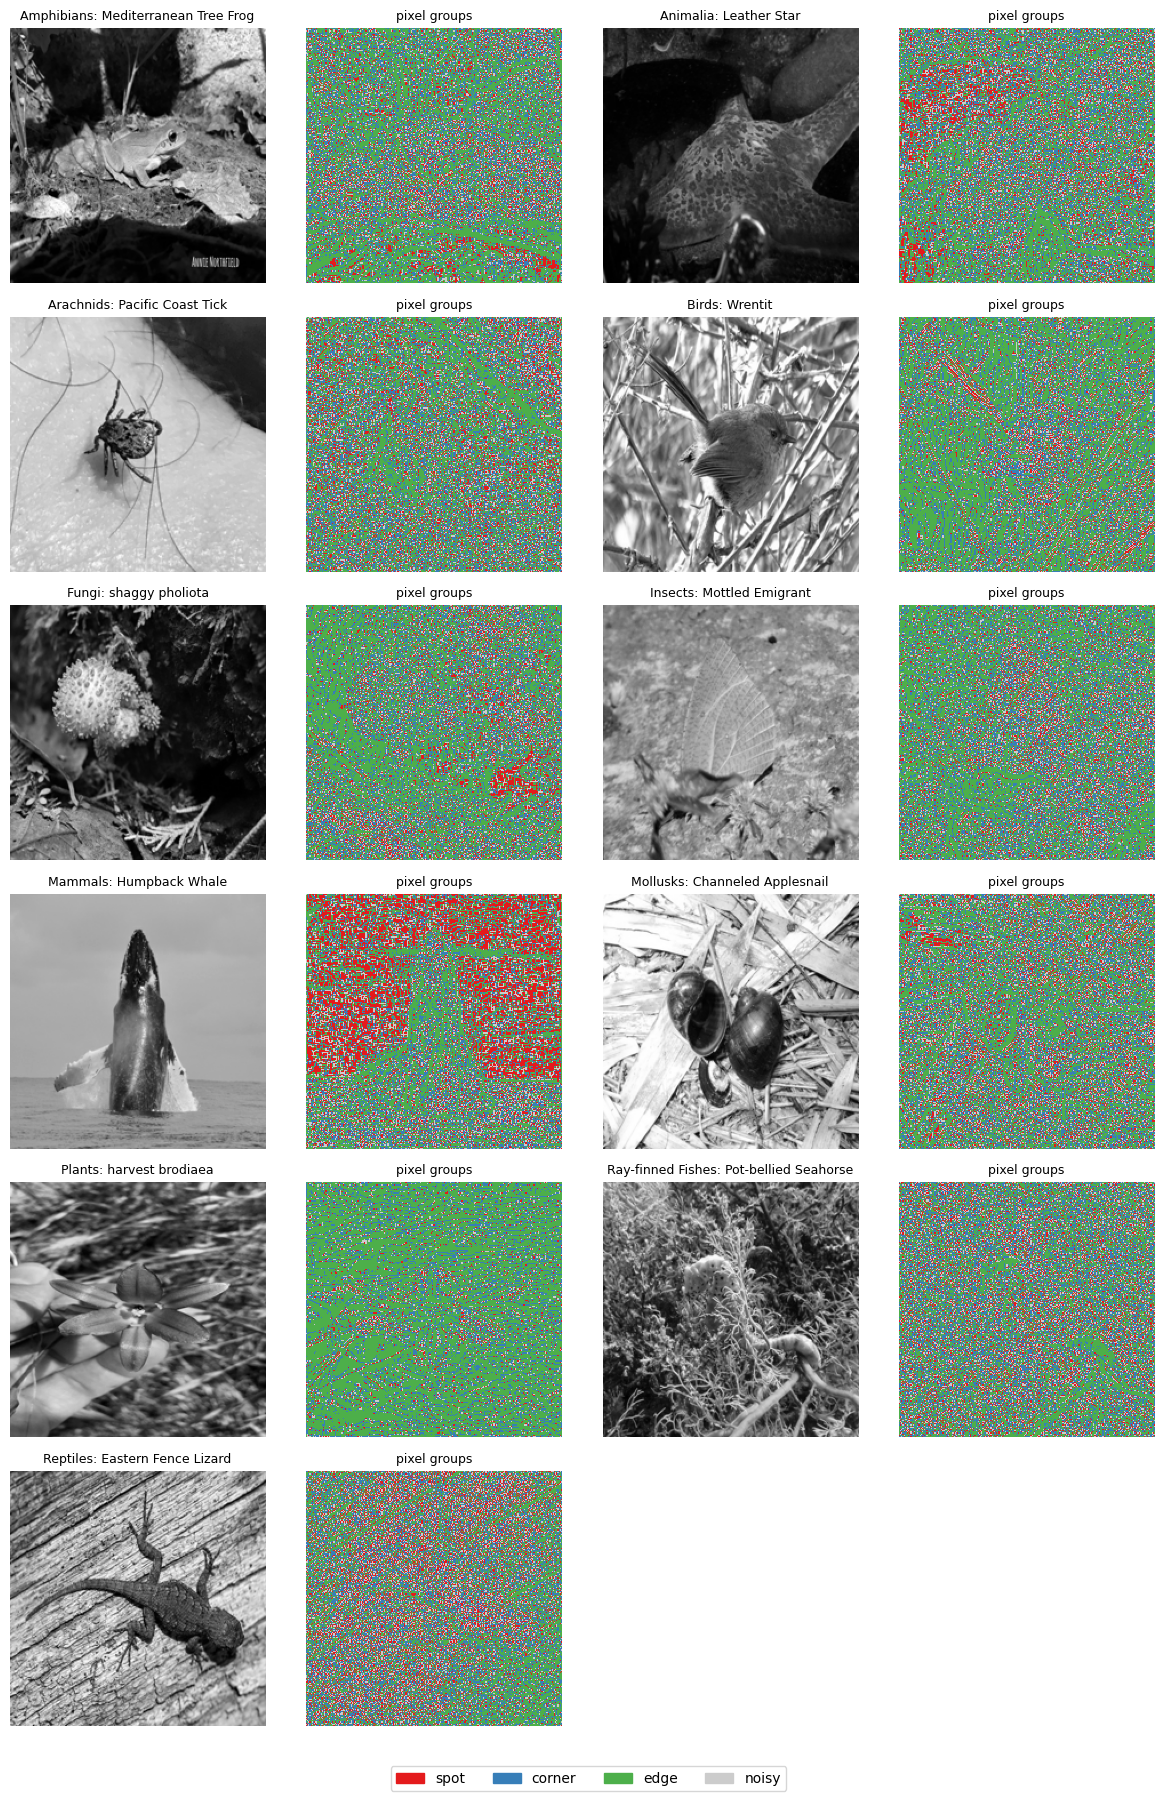

In [20]:
sample = metadata.groupby(LABEL_COLUMN).sample(n=1, random_state=1)   # one example per class
colors = ["#e41a1c", "#377eb8", "#4daf4a", "#cccccc"]   # spot, corner, edge, noisy

fig, axs = plt.subplots(6, 4, figsize=(12, 18))
for ax in axs.ravel():
    ax.axis("off")
for k, (_, row) in enumerate(sample.iterrows()):
    r, c = divmod(k, 2)
    gray = np.array(Image.open(IMG_DIR / row["file_name"]).convert("L").resize((IMG_SIZE, IMG_SIZE)))
    codes = local_binary_pattern(gray, 8, 1, method="uniform").astype(int)
    axs[r, 2 * c].imshow(gray, cmap="gray")
    axs[r, 2 * c].set_title(f"{row[LABEL_COLUMN]}: {row['common_name']}", fontsize=9)
    axs[r, 2 * c + 1].imshow(code_to_group(8)[codes], cmap=ListedColormap(colors), vmin=0, vmax=3, interpolation="nearest")
    axs[r, 2 * c + 1].set_title("pixel groups", fontsize=9)
fig.legend(handles=[Patch(color=c, label=g) for c, g in zip(colors, GROUPS)], loc="lower center", ncol=4)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

In [21]:
pd.DataFrame(G[:, 0, :], columns=GROUPS).groupby(y).mean().round(3)

,spot,corner,edge,noisy
Amphibians,0.132,0.277,0.487,0.105
Animalia,0.138,0.291,0.457,0.114
Arachnids,0.131,0.258,0.513,0.098
Birds,0.167,0.263,0.468,0.102
Fungi,0.115,0.283,0.501,0.101
Insects,0.127,0.261,0.512,0.100
Mammals,0.148,0.303,0.426,0.123
Mollusks,0.133,0.284,0.476,0.108
Plants,0.113,0.282,0.504,0.101
Ray-finned Fishes,0.142,0.287,0.460,0.112


## 5. Signal test

Same as before: 15% test split held out, 5-fold CV on the rest, logistic regression. Chance is 9%.
The two baselines to beat are **raw LBP (about 25.7%)** and **color + raw LBP (about 26.6%)**.

In [22]:
idx = np.arange(len(y))
idx_dev, idx_test = train_test_split(idx, test_size=0.15, stratify=y, random_state=SEED)   # same split as before

sets = {
    "color (baseline)": COLOR,
    "raw LBP (baseline)": RAW,
    "grouped": grouped,
    "grouped + entropy": grouped_ent,
    "color + raw LBP (baseline)": np.hstack([COLOR, RAW]),
    "color + grouped + entropy": np.hstack([COLOR, grouped_ent]),
}

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
make_clf = lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))

rows = []
for name, X in sets.items():
    r = cross_validate(make_clf(), X[idx_dev], y[idx_dev], cv=cv, scoring=["accuracy", "f1_macro"], n_jobs=-1)
    rows.append({"features": name, "dims": X.shape[1], "acc": r["test_accuracy"].mean(),
                 "acc std": r["test_accuracy"].std(), "macro-F1": r["test_f1_macro"].mean()})
results = pd.DataFrame(rows).set_index("features")
print(f"chance = {1 / len(categories):.3f}")
results.round(3)

chance = 0.091


,dims,acc,acc std,macro-F1
features,,,,
color (baseline),48,0.194,0.033,0.184
raw LBP (baseline),54,0.258,0.014,0.252
grouped,12,0.194,0.017,0.167
grouped + entropy,15,0.202,0.008,0.180
color + raw LBP (baseline),102,0.267,0.014,0.259
color + grouped + entropy,63,0.236,0.032,0.227


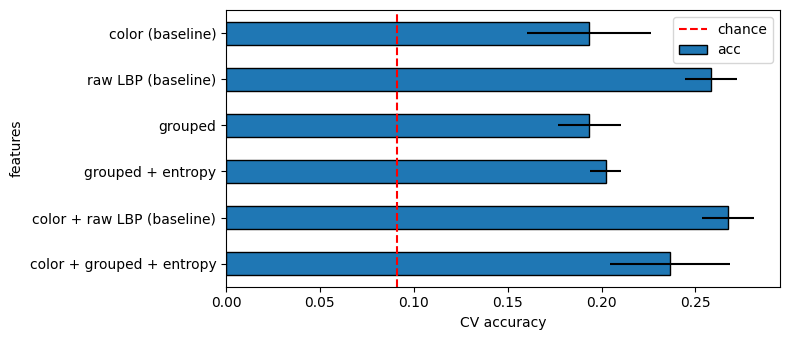

In [23]:
fig, ax = plt.subplots(figsize=(8, 3.5))
results["acc"].plot.barh(xerr=results["acc std"], ax=ax, edgecolor="black")
ax.axvline(1 / len(categories), color="red", ls="--", label="chance")
ax.invert_yaxis(); ax.set_xlabel("CV accuracy"); ax.legend()
plt.tight_layout()
plt.show()

In [24]:
np.savez(FEATURE_DIR / "lbp_grouped_features.npz", y=y, image_id=metadata["image_id"].to_numpy(),
         idx_dev=idx_dev, idx_test=idx_test, grouped=grouped, grouped_ent=grouped_ent)
print("Saved", FEATURE_DIR / "lbp_grouped_features.npz")

Saved features/lbp_grouped_features.npz
